## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [ ]:
# Your Phase 1 solution to the problem goes here.

# Question 1.1 & 1.2 : Import code & create scatterplots

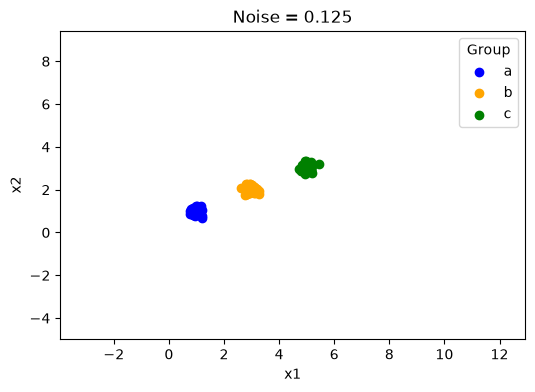

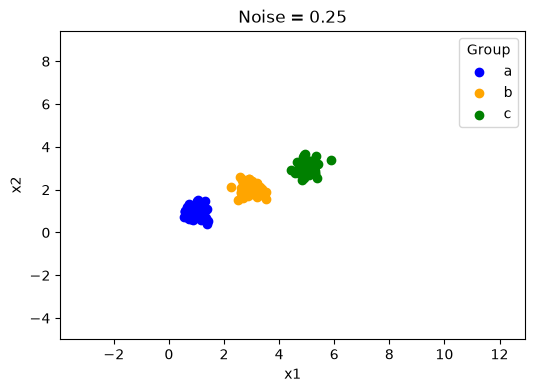

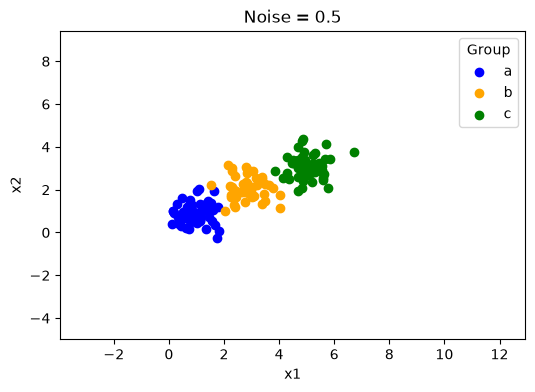

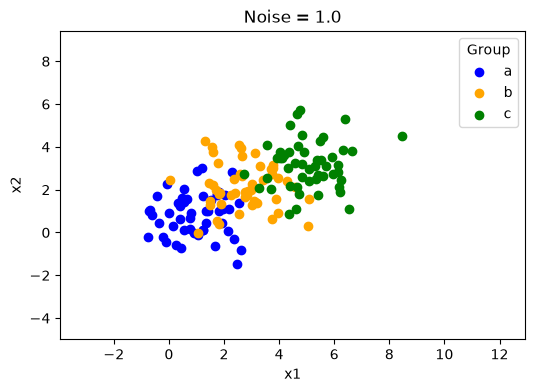

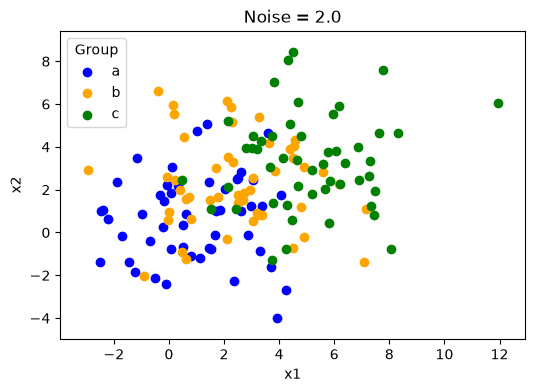

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# start of Question 1.2
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]

x_min = df2_0["x1"].min() - 1
x_max = df2_0["x1"].max() + 1
y_min = df2_0["x2"].min() - 1
y_max = df2_0["x2"].max() + 1

for i in range(5):
    df = datasets[i]
    group_a = df[df["group"] == "a"]
    group_b = df[df["group"] == "b"]
    group_c = df[df["group"] == "c"]

    plt.figure(figsize=(6, 4))
    plt.scatter(group_a["x1"], group_a["x2"], color="blue", label="a")
    plt.scatter(group_b["x1"], group_b["x2"], color="orange", label="b")
    plt.scatter(group_c["x1"], group_c["x2"], color="green", label="c")

    plt.title("Noise = " + str(noise_levels[i]))
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.legend(title="Group")
    plt.show()

# Question 1.3 : Creates a scree plot

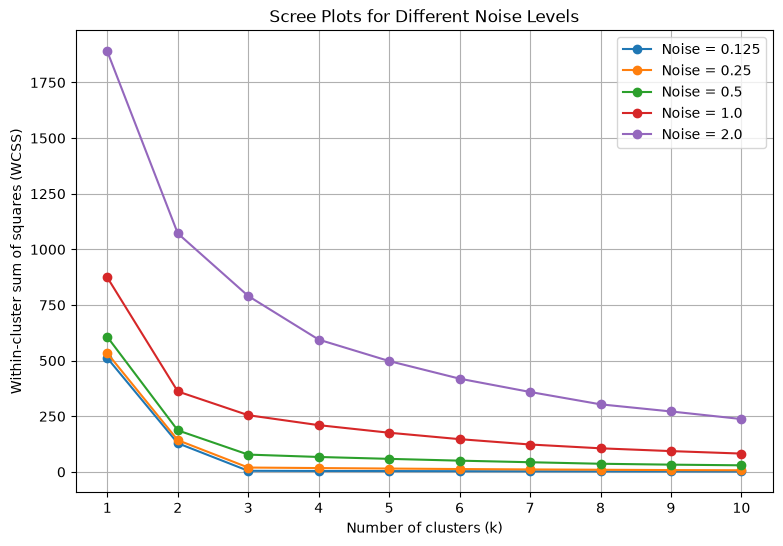

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# start of Question 1.3
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]

k_values = range(1, 11)

plt.figure(figsize=(9, 6))

for i in range(5):
    df = datasets[i]
    X = df[["x1", "x2"]]
    wcss = []

    for k in k_values:
        model = KMeans(n_clusters=k, random_state=100, n_init=10)
        model.fit(X)
        wcss.append(model.inertia_)

    plt.plot(k_values, wcss, marker="o",
             label="Noise = " + str(noise_levels[i]))

plt.title("Scree Plots for Different Noise Levels")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares (WCSS)")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

# Question 1.4 : Explain intuition of the elbow

The elbow is the point at which adding more clusters provides little improvement to the fit. When the noise levels are lower, the three groups can be easily differentiated, so any k potentially below 4 is a good choice. Adding more clusters also provides little improvement to the fit. When noise levels are higher, the groups start to mash together, which makes it more difficult to spot the elbow and choose a k value.

# Question 2.1 & 2.2 : Loading csv file & Clustering spending and Spending per Capita
I see countried divided into four clusters, where most of the dots are near the left side of the graph; this means most of the countries has low total military spending compared to the US. I also see that their spending per capita varies, so the dots spread upwards. 

The United States is the green dot in cluster 2. It has a higher total military spending than the other countries shown, though it does not have the most spending per capita. 

A pattern I noticed is that the spending per capita is the separating factor for most countries, meaning it is the main facter as to how countries are grouped. 

Number of countries: 148
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


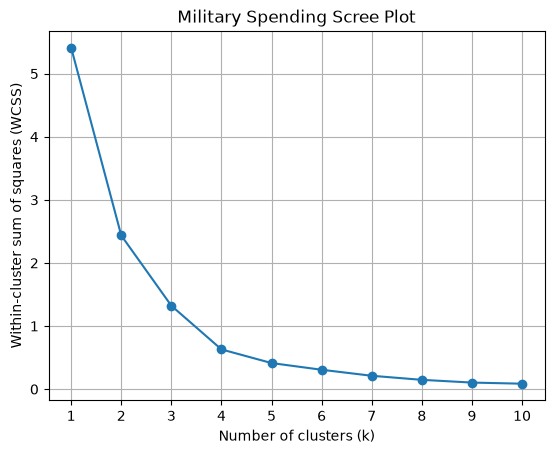

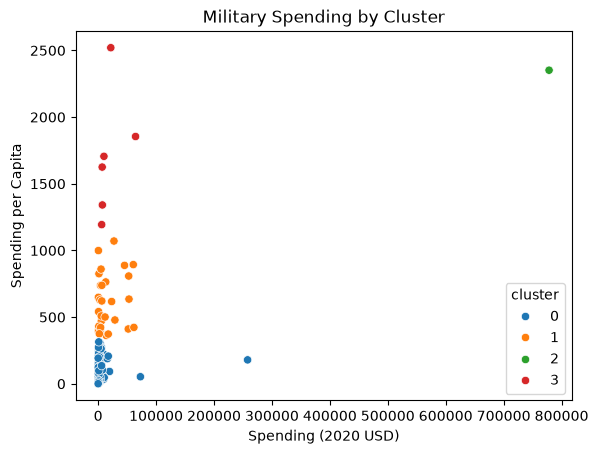

['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP', 'Percent of Government Spending', 'Spending per Capita', 'cluster']


,Country,cluster,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


In [ ]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")

df2020 = df[df["Year"] == 2020].copy()
df2020 = df2020.dropna()

print("Number of countries:", len(df2020))
print(df2020.dtypes)
df2020.head()

# start of Question 2.2
columns = ["Spending (2020 USD)", "Spending per Capita"]
scaler = MinMaxScaler()
X = scaler.fit_transform(df2020[columns])

k_values = range(1, 11)
wcss = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

plt.plot(k_values, wcss, marker="o")
plt.title("Military Spending Scree Plot")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares (WCSS)")
plt.xticks(k_values)
plt.grid(True)
plt.show()

k = 4
model = KMeans(n_clusters=k, random_state=100, n_init=10)
df2020["cluster"] = model.fit_predict(X)

sns.scatterplot(
    data=df2020,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster",
    palette="tab10"
)
plt.title("Military Spending by Cluster")
plt.show()

df2020.groupby("cluster")[columns].describe()
print(df2020.columns.tolist())

df2020[
    df2020["Country"].str.contains(
        "United States|USA", case=False, na=False
    )
][["Country", "cluster"] + columns]
df2020.groupby("cluster")[columns].describe()

# Question 2.3 : Percent of Government Spending & GDP
Compared to part 2, the results from clustering in question 2.2. Our results fro 2.3 show that the US spends more than any other country. The analysis also shows that the US is part of a larger group of countries that spend a lot on military.

Number of countries: 148


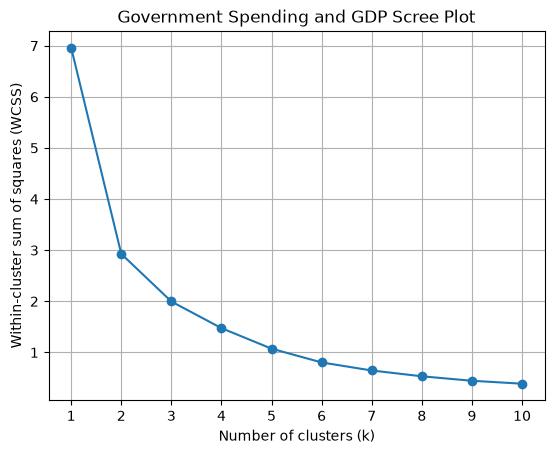

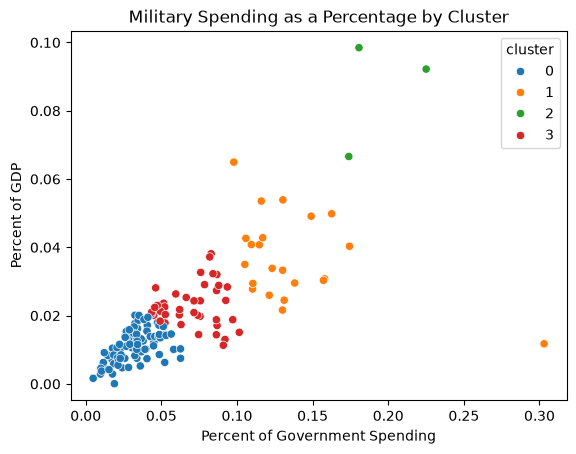

,Country,cluster,Percent of Government Spending,Percent of GDP
5540,United States of America,3,0.081976,0.037179


Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 83.0  0.032552  0.013192  0.004896   
1                                 22.0  0.136158  0.042661  0.097882   
2                                  3.0  0.193209  0.027779  0.173924   
3                                 40.0  0.070664  0.017720  0.043592   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.022839  0.032524  0.040564  0.062685           83.0  0.011094   
1        0.111561  0.126638  0.146304  0.303027           22.0  0.036932   
2        0.177289  0.180654  0.202852  0.225050            3.0  0.085760   
3        0.052339  0.074328  0.086389  0.101501           40.0  0.022824   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.004627  0.000054  0.007500  0.011015  0.014322  0.020095  
1        0.012381  0.011742  0.029458  0.034419  0.042766  0.064961  
2        0.016886  0.066600  0.079405  0.092211  0.095341  0.098470  
3        0.006231  0.011317  0.018798  0.021527  0.026590  0.038118

In [12]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")

df2020 = df[df["Year"] == 2020].copy()
df2020 = df2020.dropna()

print("Number of countries:", len(df2020))

columns = ["Percent of Government Spending", "Percent of GDP"]
scaler = MinMaxScaler()
X = scaler.fit_transform(df2020[columns])
k_values = range(1, 11)
wcss = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

plt.figure()
plt.plot(k_values, wcss, marker="o")
plt.title("Government Spending and GDP Scree Plot")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares (WCSS)")
plt.xticks(k_values)
plt.grid(True)
plt.show()

k = 4

model = KMeans(n_clusters=k, random_state=100, n_init=10)
df2020["cluster"] = model.fit_predict(X)

plt.figure()
sns.scatterplot(
    data=df2020,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster",
    palette="tab10"
)
plt.title("Military Spending as a Percentage by Cluster")
plt.show()

display(
    df2020[
        df2020["Country"].str.contains(
            "United States|USA", case=False, na=False
        )
    ][["Country", "cluster"] + columns]
)

display(df2020.groupby("cluster")[columns].describe())

# Question 2.4
The results from Question 2.2 show that the US spends a lot of money on defense. Question 2.3 compares this to the clustering results, which showed that the US was not the only high spender in defense; instead, there was a larger group of countries with similar high military spending.

Number of countries: 148
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


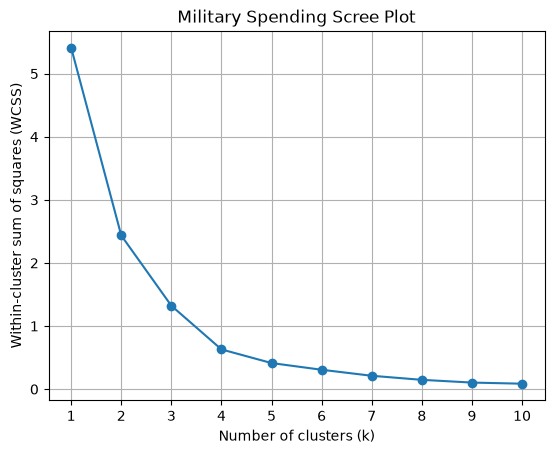

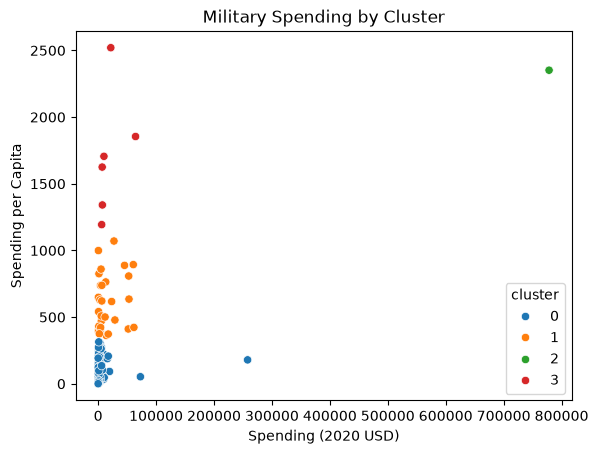

['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP', 'Percent of Government Spending', 'Spending per Capita', 'cluster']


,Country,cluster,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


In [ ]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")

df2020 = df[df["Year"] == 2020].copy()
df2020 = df2020.dropna()

print("Number of countries:", len(df2020))
print(df2020.dtypes)
df2020.head()

# start of Question 2.2
columns = ["Spending (2020 USD)", "Spending per Capita"]
scaler = MinMaxScaler()
X = scaler.fit_transform(df2020[columns])

k_values = range(1, 11)
wcss = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

plt.plot(k_values, wcss, marker="o")
plt.title("Military Spending Scree Plot")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares (WCSS)")
plt.xticks(k_values)
plt.grid(True)
plt.show()

k = 4
model = KMeans(n_clusters=k, random_state=100, n_init=10)
df2020["cluster"] = model.fit_predict(X)

sns.scatterplot(
    data=df2020,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster",
    palette="tab10"
)
plt.title("Military Spending by Cluster")
plt.show()

df2020.groupby("cluster")[columns].describe()
print(df2020.columns.tolist())

df2020[
    df2020["Country"].str.contains(
        "United States|USA", case=False, na=False
    )
][["Country", "cluster"] + columns]
df2020.groupby("cluster")[columns].describe()

Number of countries: 148


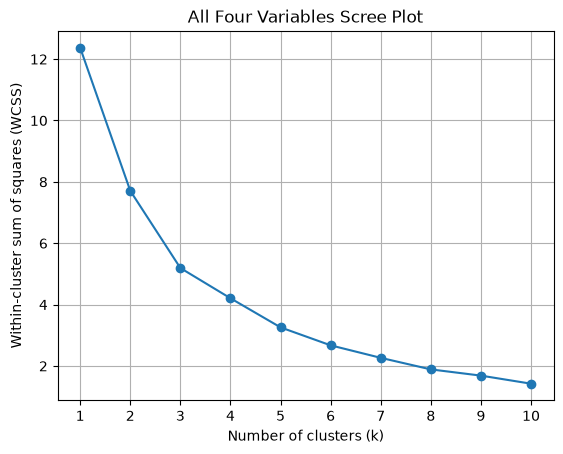

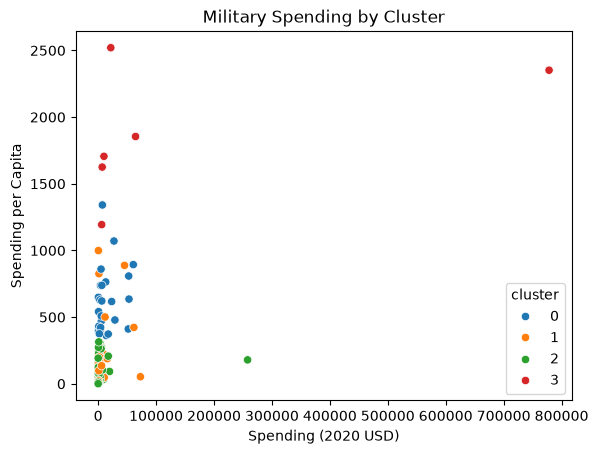

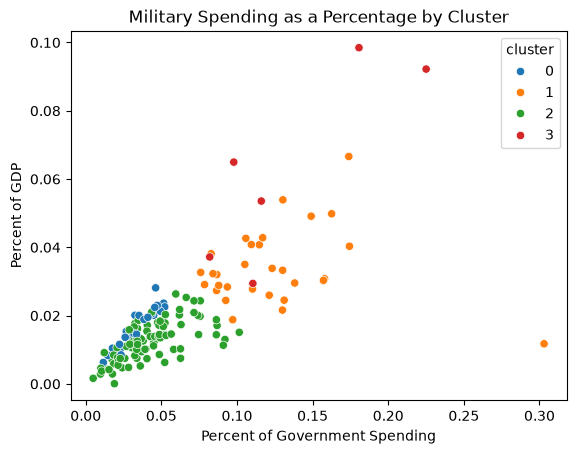

,Country,cluster,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
5540,United States of America,3,778397.2,2351.631858,0.081976,0.037179


Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      26.0   15330.618681   18923.469359   405.790494   
1                      30.0    9073.543709   18135.032885   163.926877   
2                      86.0    4513.543790   27841.230783     8.622460   
3                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0        3176.345598   5857.060906  21818.934764   60675.039625   
1         522.737081   1663.090134   8646.648849   72937.064048   
2          81.022976    288.061512   1138.618231  257973.429834   
3        7700.424616  15897.570598  53872.942442  778397.200000   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      26.0   612.677541  ...                       0.044645   
1                      30.0   215.920971  ...                       0.136403   
2                      86.0    70.290644  ...                       0.053006   
3                       6.0  1875.150751  ...                       0.164503   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.052209           26.0  0.016585  0.005525  0.006273  0.013689   
1        0.303027           30.0  0.034105  0.011116  0.011742  0.027933   
2        0.101501           86.0  0.012481  0.005799  0.000054  0.007811   
3        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   

                                       
              50%       75%       max  
cluster                                
0        0.015324  0.020431  0.028132  
1        0.032148  0.040637  0.066600  
2        0.012532  0.016783  0.026340  
3        0.059257  0.085398  0.098470  

[4 rows x 32 columns]

In [13]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")

df2020 = df[df["Year"] == 2020].copy()
df2020 = df2020.dropna()

print("Number of countries:", len(df2020))

columns = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

scaler = MinMaxScaler()
X = scaler.fit_transform(df2020[columns])

k_values = range(1, 11)
wcss = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

plt.figure()
plt.plot(k_values, wcss, marker="o")
plt.title("All Four Variables Scree Plot")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares (WCSS)")
plt.xticks(k_values)
plt.grid(True)
plt.show()

k = 4

model = KMeans(n_clusters=k, random_state=100, n_init=10)
df2020["cluster"] = model.fit_predict(X)

plt.figure()
sns.scatterplot(
    data=df2020,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster",
    palette="tab10"
)
plt.title("Military Spending by Cluster")
plt.show()

plt.figure()
sns.scatterplot(
    data=df2020,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster",
    palette="tab10"
)
plt.title("Military Spending as a Percentage by Cluster")
plt.show()

usa = df2020[df2020["Country"] == "United States of America"]
display(usa[["Country", "cluster"] + columns])

cluster_summary = df2020.groupby("cluster")[columns].describe()
display(cluster_summary)

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]